#Intro. to RS Exercise 6
Authors: Seyedeh Sharareh Mirzargar and Joël Luca Zuber

#Code

In [1]:
import pandas as pd
import numpy as np
import metrics_lib as ml
import matplotlib.pyplot as plt
! pip install surprise
from surprise import Reader, SVD, Dataset
from surprise.model_selection import train_test_split

     |████████████████████████████████| 11.8MB 5.3MB/s 
  Created wheel for scikit-surprise: filename=scikit_surprise-1.1.1-cp37-cp37m-linux_x86_64.whl size=1617614 sha256=b579a9209059476e5e31132151608cede91853b5c78015a3ffaeb15009230f59
  Stored in directory: /root/.cache/pip/wheels/78/9c/3d/41b419c9d2aff5b6e2b4c0fc8d25c538202834058f9ed110d0
Successfully built scikit-surprise


In [2]:
#Modify the location of the csv file accordingly
ratings = pd.read_csv('/content/drive/MyDrive/ratings.csv')
ratings = ratings.query('rating >=3')
ratings.reset_index(drop=True, inplace=True)

In [3]:
#only consider ratings from users who have rated over n movies
n=1000
users = ratings.userId.value_counts()
users = users[users>n].index.tolist()
ratings = ratings.query('userId in @users')
print(ratings.head(3))

       userId  movieId  rating   timestamp
15918     156        1     5.0  1037739266
15919     156        2     5.0  1040937649
15920     156        4     3.0  1038801803


In [4]:
# get movie features
rated_movies = ratings.movieId.tolist()
#Modify the location of the csv file accordingly
movies = pd.read_csv('/content/drive/MyDrive/movies.csv')
movies = movies.query('movieId in @rated_movies')
movies.set_index("movieId", inplace=True, drop=True)

movies = movies.genres.str.split("|", expand=True)
movies.reset_index(inplace=True)
movies = pd.melt(movies, id_vars='movieId', value_vars=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9])
movies.drop_duplicates("movieId", inplace=True)
movies.set_index('movieId', inplace=True)
movies = pd.get_dummies(movies.value)
#movies = movies[['Action', 'Romance', 'Western', 'Comedy', 'Crime']]
print(movies.head())

         (no genres listed)  Action  Adventure  ...  Thriller  War  Western
movieId                                         ...                        
1                         0       0          1  ...         0    0        0
2                         0       0          1  ...         0    0        0
3                         0       0          0  ...         0    0        0
4                         0       0          0  ...         0    0        0
5                         0       0          0  ...         0    0        0

[5 rows x 20 columns]


##Long tail plot

/usr/local/lib/python3.7/dist-packages/seaborn/_decorators.py:43: FutureWarning: Pass the following variable as a keyword arg: x. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  FutureWarning


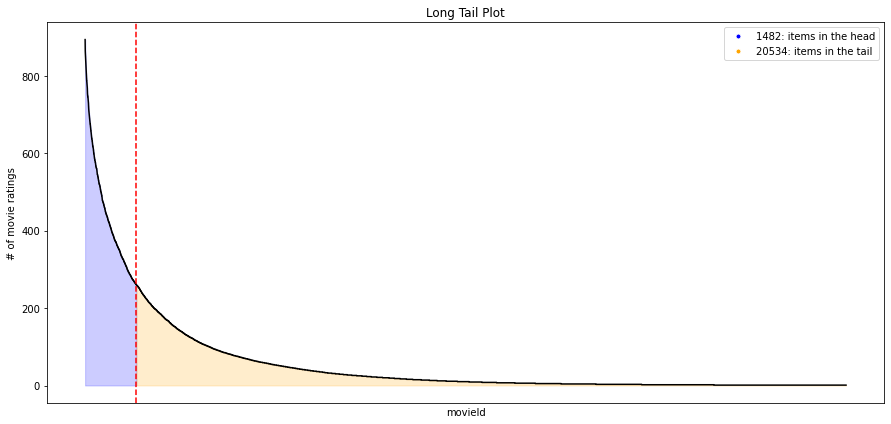

In [5]:
#LONG TAIl PLOT
fig = plt.figure(figsize=(15, 7))
ml.long_tail_plot(df=ratings,
             item_id_column="movieId",
             interaction_type="movie ratings",
             percentage=0.5,
             x_labels=False)

##COLLABORATIVE FILTERING RECOMMENDER

In [6]:

#*******************COLLABORATIVE FILTERING RECOMMENDER*************************
##format data for surprise
reader = Reader(rating_scale=(0, 5))
data = Dataset.load_from_df(ratings[['userId', 'movieId', 'rating']], reader)
trainset, testset = train_test_split(data, test_size=0.25)

#train SVD recommender
algo = SVD()
algo.fit(trainset)

#make predictions on test set.
test = algo.test(testset)
test = pd.DataFrame(test)
test.drop("details", inplace=True, axis=1)
test.columns = ['userId', 'movieId', 'current', 'cf_predictions']

cf_model = test.pivot_table(index='userId', columns='movieId', values='cf_predictions').fillna(0)


#get example prediction
#get_users_predictions(156, 10, cf_model)

#format test data
test = test.copy().groupby('userId')['movieId'].agg([ml.actual])

#make recommendations for all members in the test data
cf_recs = [] = []
for user in test.index:
    cf_predictions = ml.get_users_predictions(user, 10, cf_model)
    cf_recs.append(cf_predictions)

test['cf_predictions'] = cf_recs


##POPULARITY RECOMMENDER

In [7]:

#*******************POPULARITY RECOMMENDER*************************
# make recommendations for all members in the test data
popularity_recs = ratings.movieId.value_counts().head(10).index.tolist()

pop_recs = []
for user in test.index:
    pop_predictions = popularity_recs
    pop_recs.append(pop_predictions)

test['pop_predictions'] = pop_recs

##RANDOM RECOMMENDER

In [8]:
#*******************RANDOM RECOMMENDER*************************

# make recommendations for all members in the test data

ran_recs = []
for user in test.index:
    random_predictions = ratings.movieId.sample(10).values.tolist()
    ran_recs.append(random_predictions)

test['random_predictions'] = ran_recs

##Test results with movies IDs recommended by users and recommendations provided by the three methods

###MAR@k


 **** SOME OF THE  PREDICTIONS RESULTS **** 

                                                   actual  ...                                 random_predictions
userId                                                     ...                                                   
156     [6, 2054, 2056, 9, 4102, 12, 2062, 15, 2065, 1...  ...  [5110, 2028, 82053, 1111, 2334, 329, 2716, 953...
208     [54272, 1537, 55814, 4103, 3079, 523, 81932, 4...  ...  [783, 32174, 2315, 44694, 71558, 1094, 912, 32...
359     [514, 7173, 45062, 5127, 1032, 4105, 41997, 54...  ...  [90249, 8528, 1291, 1259, 608, 60, 2647, 5617,...
394     [1537, 514, 1028, 3588, 6662, 6663, 6666, 5633...  ...  [1280, 1069, 3174, 53468, 2657, 2916, 235, 109...
572     [2, 514, 54276, 516, 5, 4104, 37384, 91658, 69...  ...  [6457, 33004, 90057, 4961, 57368, 4621, 45732,...

[5 rows x 4 columns]


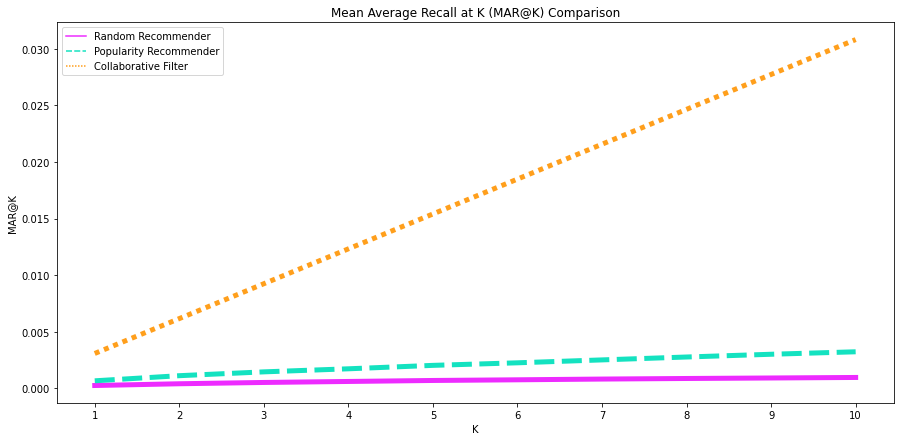

In [9]:
#*********** Test results with movies IDs recommended by users and recommendations provided by the three methods
print("\n **** SOME OF THE  PREDICTIONS RESULTS **** \n")
print(test.head())

actual = test.actual.values.tolist()
cf_predictions = test.cf_predictions.values.tolist()
pop_predictions = test.pop_predictions.values.tolist()
random_predictions = test.random_predictions.values.tolist()

#Computing the minimum recall for every recommender system

pop_mark = []
for K in np.arange(1, 11):
    pop_mark.extend([ml.mark(actual, pop_predictions, k=K)])

random_mark = []
for K in np.arange(1, 11):
    random_mark.extend([ml.mark(actual, random_predictions, k=K)])

cf_mark = []
for K in np.arange(1, 11):
    cf_mark.extend([ml.mark(actual, cf_predictions, k=K)])

#MEAN AVERAGE RECALL @ K

mark_scores = [random_mark, pop_mark, cf_mark]
index = range(1,10+1)
names = ['Random Recommender', 'Popularity Recommender', 'Collaborative Filter']
fig = plt.figure(figsize=(15, 7))
ml.mark_plot(mark_scores, model_names=names, k_range=index)

#COVERAGE
catalog = ratings.movieId.unique().tolist()
random_coverage = ml.prediction_coverage(ran_recs, catalog)
pop_coverage = ml.prediction_coverage(pop_recs, catalog)
cf_coverage = ml.prediction_coverage(cf_recs, catalog)

# N=100 observed recommendation lists
random_cat_coverage = ml.catalog_coverage(ran_recs, catalog, 100)
pop_cat_coverage = ml.catalog_coverage(pop_recs, catalog, 100)
cf_cat_coverage = ml.catalog_coverage(cf_recs, catalog, 100)

###prediction coverage

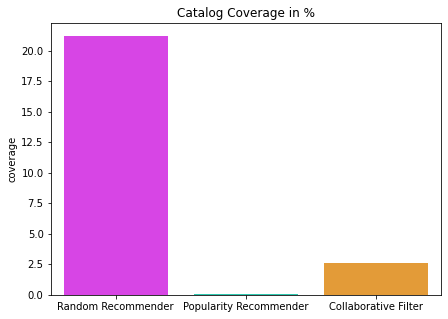

In [10]:
# plot of prediction coverage
coverage_scores = [random_coverage, pop_coverage, cf_coverage]
model_names = ['Random Recommender', 'Popularity Recommender', 'Collaborative Filter']

fig = plt.figure(figsize=(7, 5))
ml.coverage_plot(coverage_scores, model_names)

###Novelty

In [11]:
#NOVELTY
print("\n **** NOVELTY METRIC **** \n")
nov = ratings.movieId.value_counts()
pop = dict(nov)
random_novelty,random_mselfinfo_list = ml.novelty(ran_recs, pop, len(users), 10)
pop_novelty,pop_mselfinfo_list = ml.novelty(pop_recs, pop, len(users), 10)
cf_novelty,cf_mselfinfo_list = ml.novelty(cf_recs, pop, len(users), 10)
print(random_novelty, pop_novelty, cf_novelty)


 **** NOVELTY METRIC **** 

2.2500623830311155 0.10697151566593387 0.6793912024984051


###Personalization
could not produce it for the random model because of "Index contains duplicate entries, cannot reshape" error

In [15]:
#personalization
print("\n **** PERSONALIZATION METRIC **** \n")
ran_recs_wtho_duplications = []
for l in ran_recs:
  duplicates = len(l) - len(set(l))
  l_wtho_duplicates = list(set(l))
  if( duplicates >0 ):
    while(duplicates >0):
      #append some invalid item
      l_wtho_duplicates.append(-10-duplicates)
      duplicates -=1
  ran_recs_wtho_duplications.append(l_wtho_duplicates)  
random_personalization = ml.personalization(ran_recs_wtho_duplications)
pop_personalization = ml.personalization(pop_recs)
cf_personalization = ml.personalization(cf_recs)
print(random_personalization,pop_personalization, cf_personalization)


 **** PERSONALIZATION METRIC **** 

0.997641555000483 1.1102230246251565e-16 0.9089756151415205


#Questions

##Long tail plot


1.   How will you describe the 1482 items that are in the head of the graph?

>> These items are popular and well-known. While these items have a rich user-item matrix and a collaborative filtering RS can produce reliable predictions for these items, many of the users already know these items as they are popular

2.   How will you describe the 20534 items that are in the tail of the graph?

>> The items in the tail have a sparse user-item matrix and usually their interactions are not enough for collaborative filtering RS systems. Based on the RS algorithm, they may rarely be recommended to users. And users do not know them well either.

3.   If a RS recommends items that are only in the head of the graph, what can you say about this RS in terms of personalization and serendipity?

>> In terms of personalization, the items in the head have high-level of interactions and recommending them will not provide a personalized exerience to the user because the user already has heard of them (e.g. recommending the Godfather to every user is not personalized). Also, in terms of serendipity, the RS performs poorly because it is biased by the popularity and does not explore well the new items which are mostly in the tail.



## Mean Average Recall @K


1.   Given that the CF model provides better MAR@K values, do you think this model will provide better recommendations than the random and popular models?

>> In terms of ordered list of k items, MAR@K shows if we have retrieved a good portion of all the relevant items. Therefore, in terms of recall, CF model is outperforming the random and popular models. If we consider other metrics (e.g. serendipity), MAR@K is not a good metric for comparison

2.   With this new information, which model do you think will perform better in terms of personalization of recommendations and serendipity?

>>MAR@K is not a good metric to compare the RSs with regard to 'serendipity' because it only focuses on: what portion of all the rellevant items has been recommended. An item might not be 'relevant' to user's interactions but produce an unexpected pleasant experience.


>>In terms of personalizations, high MAR@K can indicate higher personalization because for each user, the set of relevant iterms might differ.

>> *We have also calculated the personalization metric for the models which will be used in the calculation part*




##Coverage


1.   Are you suprised that the random recommender shows a higher coverage than the other two models? Please explain why/why not.

>>No, It is expected that the random RS, has a very high coverage because when producing recommendatons, it freely explores the item space and each time produces completely independet recommendations.

2.   With this new information, which model do you think will perform better in terms of personalization of recommendations and serendipity?

>>**random**: better in terms of 'serendipity' \\
>>**CF**: better in terms of 'personalization' \\
>>**popular**: performs poorly in both of 'personalization' and 'serendipity'

>>*We have also calculated the personalization metric for the models which will be used in the calculation part*



##Novelty


1.   Which model do you think will perform better in terms of personalization of recommendations and serendipity?

>> The random model has a novelty score of '2.27' which shows that this model provides a high level of serendipity. The CF model is the next with a novelty score of '0.69' which shows that its serendipity is much less than the random model. The popular model performs has the lowest novelty score. Regarding the personalization, by just looking at the novelty, we can not say much except that the random model by its construction has very low personalization.

>>*We have also calculated the personalization metric for the models which will be used in the calculation part*



##conclusions

1.   Which model will you define as the overall best?

>> CF model

2.   When you think exclusively in terms of personalization and serendepity, which one do you consider the best model?

>> *   In terms of both personalization and serendipity: None of them. **Note: while the random model receives a high personalization score, it is not personalized by its construction because it does not take into account the taste and preferences of the users while generating recommendations. Its high personalization score is dues to the fact that personalization score only focus on how much the recommendations for each user is different from the other users. Therefore, personalization metric by its own is not enough for deciding whether a model is personalized or not.**
>> *  In terms of personalization: CF model
>> *  In terms of serendipity: random


3.   If you have to pick one to implement in a real-life movies recommendation application, which model would you select to implement and why?

>> By looking at the given metrics in this exercise, none of the models provide all the desired properties at the same time. While random model performs well in terms of serendipity and coverage, it has a low MAR@k and it is not a personalized model by its construction (eventhough the personalization metric is high for this model, it is just because the random model produces very different recommendations for each user but it does not consider the taste and preferences of the user. Therefore, its recommendations will decrease the user trust in the system). On the other hand, CF model has low coverage and serendipity but it has high MAR@k and personalization scores.

